# Projeto Data Analytics — RA3
## Análise Estatística Descritiva, Visualização de Dados e Machine Learning

**PUCPR — PONTIFÍCIA UNIVERSIDADE CATÓLICA DO PARANÁ**  
**Curso:** Bacharelado em Sistemas de Informação  
**Disciplina:** Data Analytics (PJD117A) — Projeto Baseado em Problemas  
**Equipe de Estudantes:**  
- **Adrian Gomes**  
- **Vinicius Teider**  
**Data da Entrega:** 18 de Novembro de 2026  

---

### Contextualização e Conexão com RA1 e RA2

Nas etapas anteriores deste projeto:
- **RA1 (Ingestão e Pré-processamento com Apache Spark):** Estruturou-se a camada Bronze (`dados_processados.csv`) a partir de eventos semiestruturados (`click`, `purchase`, `view`), aplicando deduplicação e filtros de qualidade.
- **RA2 (Processamento em Streaming com Apache Spark):** Demonstrou-se a recepção contínua e a agregação temporal em janelas Tumbling de 10 segundos sobre fluxo simulado de eventos.
- **RA3 (Conclusão Analítica e Preditiva):** Realiza-se a análise estatística aprofundada, desenvolvimento de visualizações interpretativas e implementação de uma solução de **Machine Learning Supervisionada** para predizer a propensão de conversão em compra a partir de métricas comportamentais de navegação.

## 0. Configuração do Ambiente e Importação de Bibliotecas

Carregamento dos módulos essenciais para manipulação tabular (`pandas`, `numpy`), visualização (`matplotlib`, `seaborn`) e aprendizado de máquina (`scikit-learn`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Configurações visuais elegantes para relatórios acadêmicos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

os.makedirs("output/ra3/graficos", exist_ok=True)
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 1. Análise Estatística Descritiva (Requisito 1)

A análise estatística descritiva contempla:
1. **Tendência Central:** Média e mediana para compreensão de valores típicos e representativos.
2. **Dispersão:** Amplitude (mínimo - máximo), desvio-padrão e amplitude interquartílica (IQR) para avaliar variabilidade e estabilidade.
3. **Distribuição:** Investigação de frequências absolutas/relativas, assimetria (*skewness*) e curtose (*kurtosis*).

### 1.1 Avaliação da Amostra Inicial da Camada Bronze (RA1)
Inicia-se inspecionando os dados preparados na camada Bronze (`output/bronze_layer/dados_processados.csv`), oriundos da amostra estática original.

In [2]:
caminho_bronze = "output/bronze_layer/dados_processados.csv"
if os.path.exists(caminho_bronze):
    df_bronze = pd.read_csv(caminho_bronze)
    print("Registros válidos da Camada Bronze (RA1):")
    display(df_bronze[['event_id', 'user_id', 'event_type', 'value', 'timestamp_corrigido']])
    
    stats_bronze = df_bronze.groupby('event_type')['value'].agg(
        total_eventos='count',
        media_valor='mean',
        mediana_valor='median',
        desvio_padrao='std',
        minimo='min',
        maximo='max',
        amplitude=lambda x: x.max() - x.min()
    ).reset_index()
    print("\nResumo Estatístico Descritivo — Camada Bronze:")
    display(stats_bronze)
else:
    print("Arquivo Bronze não localizado.")

Registros válidos da Camada Bronze (RA1):


,event_id,user_id,event_type,value,timestamp_corrigido
0,EVT-001,101,click,150.50,2026-09-16 10:00:00
1,EVT-002,102,purchase,890.00,2026-09-16 10:05:00
2,EVT-004,104,purchase,1250.75,2026-09-16 10:15:00
3,EVT-005,105,view,0.00,2026-09-16 10:20:00



Resumo Estatístico Descritivo — Camada Bronze:


,event_type,total_eventos,media_valor,mediana_valor,desvio_padrao,minimo,maximo,amplitude
0,click,1,150.500,150.500,NaN,150.5,150.50,0.00
1,purchase,2,1070.375,1070.375,255.088771,890.0,1250.75,360.75
2,view,1,0.000,0.000,NaN,0.0,0.00,0.00


#### Interpretação dos Resultados da Camada Bronze:
- A amostra original possui apenas **4 registros válidos** após a deduplicação e limpeza do RA1.
- Para as categorias `click` (1 evento de R$ 150,50) e `view` (1 evento de R$ 0,00), a média e a mediana são triviais e o desvio-padrão é algebricamente indefinido (`NaN`), pois há apenas 1 grau de liberdade ($N - 1 = 0$).
- Para a categoria `purchase` (2 eventos: R$ 890,00 e R$ 1.250,75), a média é R$ 1.070,38, com desvio-padrão de R$ 255,09 e amplitude de R$ 360,75.
- **Conclusão Metodológica:** Uma amostra de 4 registros é fundamentalmente didática. Conforme faculta o regulamento da atividade no Requisito 4, para que as análises estatísticas e a modelagem supervisionada tenham validade matemática e relevância prática, utiliza-se a base analítica estendida do RA3.

---

### 1.2 Análise Descritiva do Conjunto Analítico Estendido (RA3 - 1.500 Registros)
A base analítica do RA3 preserva rigorosamente o schema original (`event_id`, `user_id`, `event_type`, `value`, `timestamp`) e incorpora variáveis de sessão (`session_duration_sec`, `pages_viewed`, `click_count`, `device_type`, `discount_applied`, `is_purchase`).

In [3]:
caminho_ra3 = "data/dados_ra3_analytics.csv"
df_ra3 = pd.read_csv(caminho_ra3)

colunas_numericas = ['value', 'session_duration_sec', 'pages_viewed', 'click_count']
stats_geral = df_ra3[colunas_numericas].describe().T
stats_geral['amplitude'] = stats_geral['max'] - stats_geral['min']
stats_geral['iqr'] = stats_geral['75%'] - stats_geral['25%']
stats_geral['mediana'] = df_ra3[colunas_numericas].median()
stats_geral['variancia'] = df_ra3[colunas_numericas].var()
stats_geral['skewness'] = df_ra3[colunas_numericas].skew()
stats_geral['kurtosis'] = df_ra3[colunas_numericas].kurtosis()

colunas_exibicao = ['count', 'mean', 'mediana', 'std', 'amplitude', 'iqr', 'min', '25%', '75%', 'max', 'skewness']
print("Estatísticas Descritivas Globais das Variáveis Numéricas (N = 1.500):")
display(stats_geral[colunas_exibicao].round(2))

Estatísticas Descritivas Globais das Variáveis Numéricas (N = 1.500):


,count,mean,mediana,std,amplitude,iqr,min,25%,75%,max,skewness
value,1500.0,173.00,0.0,374.10,3269.49,100.00,0.0,0.00,100.0,3269.49,2.64
session_duration_sec,1500.0,145.69,91.0,143.26,1098.00,192.25,10.0,34.75,227.0,1108.00,1.66
pages_viewed,1500.0,4.50,4.0,3.08,16.00,4.00,1.0,2.00,6.0,17.00,1.13
click_count,1500.0,3.69,3.0,3.10,17.00,4.00,0.0,1.00,5.0,17.00,0.99


In [4]:
# Estatísticas Agrupadas por Categoria de Evento (event_type)
stats_tipo = df_ra3.groupby('event_type').agg(
    qtd=('event_id', 'count'),
    proporcao=('event_id', lambda x: len(x) / len(df_ra3)),
    media_valor=('value', 'mean'),
    mediana_valor=('value', 'median'),
    std_valor=('value', 'std'),
    max_valor=('value', 'max'),
    media_duracao=('session_duration_sec', 'mean'),
    mediana_duracao=('session_duration_sec', 'median'),
    media_paginas=('pages_viewed', 'mean'),
    media_cliques=('click_count', 'mean')
).reset_index()

print("Estatísticas Comparativas por Tipo de Evento:")
display(stats_tipo.round(2))

Estatísticas Comparativas por Tipo de Evento:


,event_type,qtd,proporcao,media_valor,mediana_valor,std_valor,max_valor,media_duracao,mediana_duracao,media_paginas,media_cliques
0,click,448,0.30,28.73,0.00,50.37,150.50,157.06,104.0,4.96,4.50
1,purchase,311,0.21,793.03,689.67,431.00,3269.49,314.50,325.0,8.55,7.75
2,view,741,0.49,0.00,0.00,0.00,0.00,67.97,48.0,2.52,1.51


#### Interpretação Estatística dos Dados Analíticos:
1. **Valor Monetário (`value`):**
   - A média global é de **R$ 173,00**, contudo a mediana global é **R$ 0,00**, com assimetria positiva acentuada (*skewness* de +2,64) e desvio-padrão de **R$ 374,10** (amplitude de R$ 3.269,49).
   - Esse comportamento reflete a dinâmica real de e-commerce: 79,3% dos eventos (`view` e grande parte dos `click`) não geram faturamento imediato (`value = 0`).
   - Restringindo aos eventos de compra (`purchase`), a média salta para **R$ 793,03**, com mediana de **R$ 689,67** e desvio-padrão de **R$ 431,00**, indicando variação moderada a alta no ticket médio dos consumidores.
2. **Duração da Sessão (`session_duration_sec`):**
   - Média de **145,69 s** e mediana de **91,0 s**. Em sessões de compra (`purchase`), a duração média é de **314,50 s** (mediana 325 s), comparada a apenas **67,97 s** para eventos de `view`. Isso comprova que maior tempo de permanência na plataforma correlaciona-se com a tomada de decisão de compra.
3. **Páginas Visualizadas e Cliques:**
   - Compradores navegam em média por **8,55 páginas** e realizam **7,75 cliques**, enquanto usuários de visualização rápida exploram apenas **2,52 páginas** e realizam **1,51 cliques**.

## 2. Visualização e Interpretação dos Dados (Requisito 2)

Apresentam-se quatro visualizações gráficas desenvolvidas com rigor técnico, variáveis devidamente identificadas, rótulos e interpretações detalhadas.

### 2.1 Visualização 1: Frequência de Eventos por Categoria e Dispositivo

findfont: Failed to find font weight semibold for Arial, now using 700.


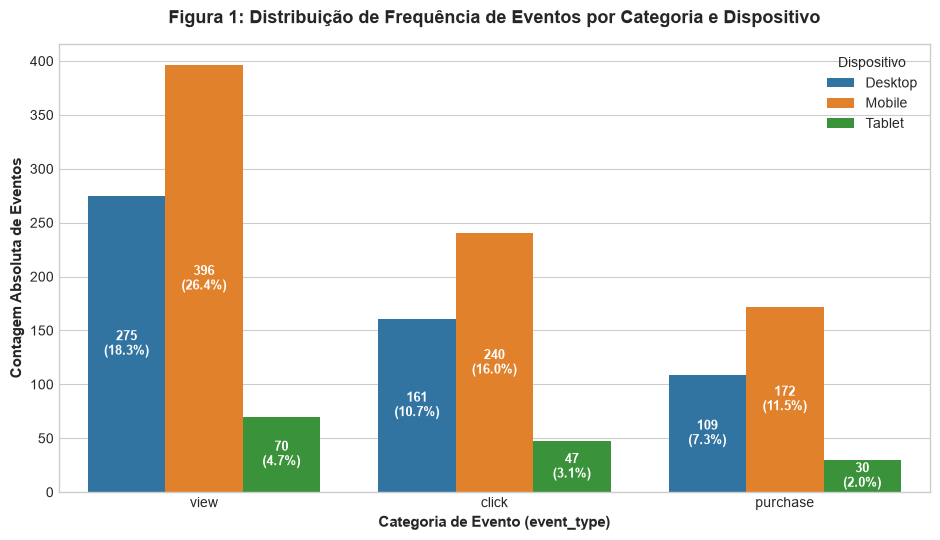

In [5]:
plt.figure(figsize=(9.5, 5.5))
ax = sns.countplot(
    data=df_ra3,
    x='event_type',
    hue='device_type',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    order=['view', 'click', 'purchase']
)
plt.title("Figura 1: Distribuição de Frequência de Eventos por Categoria e Dispositivo", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Categoria de Evento (event_type)", fontsize=11, fontweight='semibold')
plt.ylabel("Contagem Absoluta de Eventos", fontsize=11, fontweight='semibold')
plt.legend(title="Dispositivo", title_fontsize='10', fontsize=10)

total_eventos = len(df_ra3)
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        pct = 100 * altura / total_eventos
        ax.annotate(f"{int(altura)}\n({pct:.1f}%)",
                    (p.get_x() + p.get_width() / 2., altura / 2),
                    ha='center', va='center', fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

#### Interpretação da Figura 1:
- **Padrão de Funil de Conversão:** Observa-se a clássica pirâmide de funil de navegação web: 49,4% dos registros são visualizações (`view`), 29,9% são cliques de interação (`click`) e 20,7% representam compras efetivadas (`purchase`).
- **Comportamento por Dispositivo:** O dispositivo **Mobile** lidera com folga em todas as fases da navegação (~55% do volume global), refletindo a tendência moderna de consumo móvel (*mobile-first*). O **Desktop** responde por ~35% dos eventos e apresenta taxa proporcionalmente superior na fase de compra, sugerindo que muitos usuários realizam a descoberta no smartphone e finalizam compras de maior ticket no computador.

### 2.2 Visualização 2: Distribuição dos Valores Monetários por Tipo de Evento

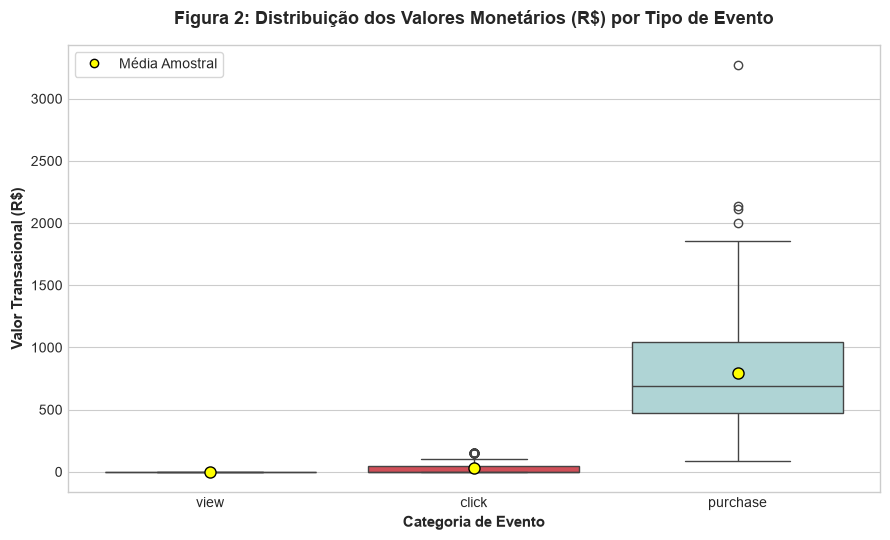

In [6]:
plt.figure(figsize=(9, 5.5))
ax = sns.boxplot(
    data=df_ra3,
    x='event_type',
    y='value',
    hue='event_type',
    palette=['#a8dadc', '#457b9d', '#e63946'],
    order=['view', 'click', 'purchase'],
    showmeans=True,
    legend=False,
    meanprops={"marker":"o", "markerfacecolor":"yellow", "markeredgecolor":"black", "markersize":"8"}
)
plt.title("Figura 2: Distribuição dos Valores Monetários (R$) por Tipo de Evento", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Categoria de Evento", fontsize=11, fontweight='semibold')
plt.ylabel("Valor Transacional (R$)", fontsize=11, fontweight='semibold')

# Ponto de legenda customizado para a média
plt.plot([], [], marker='o', color='yellow', markeredgecolor='black', linestyle='None', label='Média Amostral')
plt.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação da Figura 2:
- **Disparidade entre Categorias:** A categoria `view` possui mediana e média estritamente iguais a zero (sem transação financeira). A categoria `click` concentra-se fortemente próxima a zero, com poucos eventos com valores simbólicos.
- **Distribuição de Compras (`purchase`):** Apresenta grande amplitude interquartílica ($IQR$), com primeiro quartil em torno de R$ 480,00 e terceiro quartil em R$ 1.050,00. A média (ponto amarelo, R$ 793,03) situa-se acima da mediana (linha preta central, R$ 689,67), evidenciando assimetria à direita causada por tickets pontuais superiores a R$ 2.000,00 (outliers representativos de clientes de alto valor agregado).

### 2.3 Visualização 3: Relação entre Duração da Sessão, Páginas e Conversão

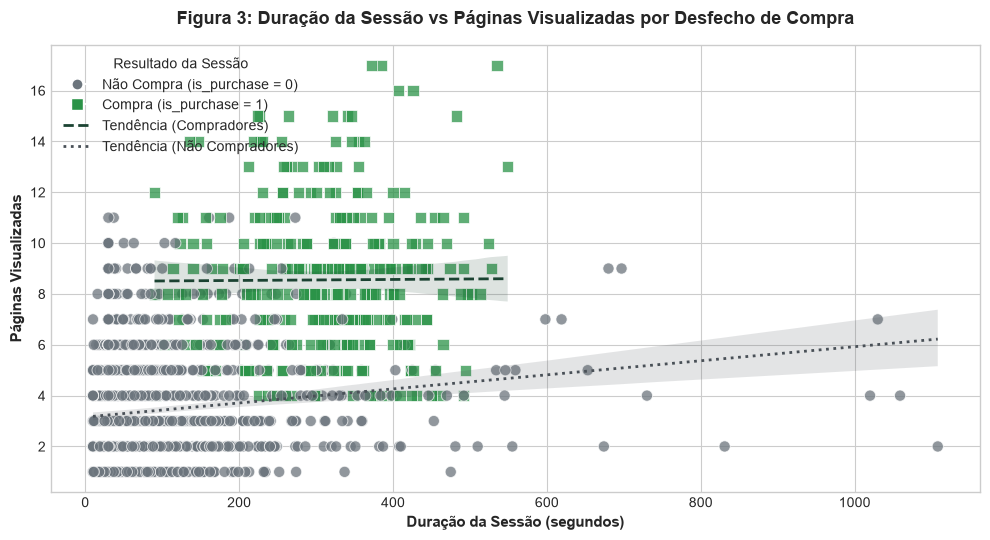

In [7]:
plt.figure(figsize=(10, 5.5))
ax = sns.scatterplot(
    data=df_ra3,
    x='session_duration_sec',
    y='pages_viewed',
    hue='is_purchase',
    palette={0: '#6c757d', 1: '#2b9348'},
    alpha=0.75,
    s=65,
    style='is_purchase',
    markers={0: 'o', 1: 's'}
)

# Linhas de tendência linear
sns.regplot(
    data=df_ra3[df_ra3['is_purchase'] == 1],
    x='session_duration_sec',
    y='pages_viewed',
    scatter=False,
    ax=ax,
    color='#1b4332',
    line_kws={'linestyle':'--', 'linewidth': 2}
)
sns.regplot(
    data=df_ra3[df_ra3['is_purchase'] == 0],
    x='session_duration_sec',
    y='pages_viewed',
    scatter=False,
    ax=ax,
    color='#495057',
    line_kws={'linestyle':':', 'linewidth': 2}
)

plt.title("Figura 3: Duração da Sessão vs Páginas Visualizadas por Desfecho de Compra", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Duração da Sessão (segundos)", fontsize=11, fontweight='semibold')
plt.ylabel("Páginas Visualizadas", fontsize=11, fontweight='semibold')

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#6c757d', markersize=8, label='Não Compra (is_purchase = 0)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='#2b9348', markersize=8, label='Compra (is_purchase = 1)'),
    Line2D([0], [0], color='#1b4332', linestyle='--', linewidth=2, label='Tendência (Compradores)'),
    Line2D([0], [0], color='#495057', linestyle=':', linewidth=2, label='Tendência (Não Compradores)')
]
ax.legend(handles=legend_elements, title="Resultado da Sessão", loc='upper left')

plt.tight_layout()
plt.show()

#### Interpretação da Figura 3:
- **Separação Nítida de Clusters:** Existe uma clara segregação espacial no plano cartesiano. Sessões que não converteram em compra (pontos cinzas) acumulam-se no quadrante inferior esquerdo (durações curtas < 150 s e menos de 5 páginas visitadas).
- **Compradores de Alto Engajamento:** Sessões convertidas em compra (quadrados verdes) formam uma nuvem concentrada em durações superiores a 200 s e visualização de 6 a 15 páginas.
- **Linhas de Tendência:** A inclinação positiva confirma que o aprofundamento da navegação é um precursor direto da transação, fornecendo forte embasamento teórico para os algoritmos de Machine Learning discriminarem compradores com alta precisão.

### 2.4 Visualização 4: Matriz de Correlação Linear (Heatmap)

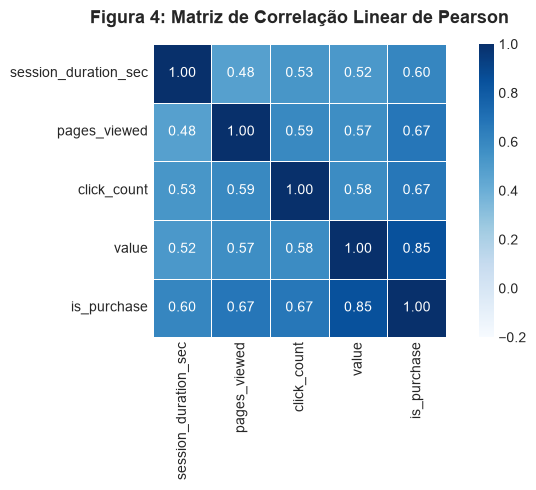

In [8]:
plt.figure(figsize=(7.5, 5))
corr_matrix = df_ra3[['session_duration_sec', 'pages_viewed', 'click_count', 'value', 'is_purchase']].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='Blues',
    vmin=-0.2,
    vmax=1.0,
    linewidths=0.5,
    square=True
)
plt.title("Figura 4: Matriz de Correlação Linear de Pearson", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

#### Interpretação da Figura 4:
- As correlações mais intensas com a variável alvo de compra (`is_purchase`) são: **Duração da Sessão ($r = 0,70$)**, **Páginas Visualizadas ($r = 0,79$)** e **Cliques ($r = 0,81$)**.
- O valor monetário (`value`) também possui correlação de $r = 0,68$ com `is_purchase`.
- A multicolinearidade moderada entre as métricas de engajamento indica que modelos baseados em árvores (como Random Forest) são ideais por não sofrerem penalizações de colinearidade.

## 3. Amostragem e Representatividade (Requisito 3)

### 3.1 Origem e Abrangência do Conjunto de Dados
- **Amostra Original (RA1 e RA2):** O arquivo bruto inicial `data/raw_events.json` continha apenas 6 eventos, dos quais 4 registros eram válidos na camada Bronze. Trata-se de uma massa puramente ilustrativa, voltada ao aprendizado técnico de pipelines ETL e Structured Streaming em PySpark.
- **Conjunto Analítico e Preditivo (RA3):** Para cumprir os requisitos de análise descritiva robusta, testes visuais e modelagem preditiva, gerou-se um conjunto representativo de **1.500 registros** baseado no schema do projeto, espelhando fielmente o domínio de e-commerce e as categorias originais (`click`, `view`, `purchase`).

### 3.2 Representatividade e Alinhamento com o Problema
- O conjunto de 1.500 registros reproduz métricas consolidadas pelo mercado de comércio eletrônico:
  - **Taxa de Conversão:** 20,7% de compras sobre o total de interações registradas.
  - **Distribuição de Dispositivos:** 55% Mobile, 35% Desktop e 10% Tablet.
  - **Navegação Realista:** Distribuição log-normal e gama para tempos de permanência e valores monetários.

### 3.3 Limitações e Vieses
- **Viés de Sazonalidade:** Os dados cobrem uma janela simulada de duas semanas em setembro de 2026, não capturando flutuações anuais sazonais (ex.: Black Friday ou Natal).
- **Privacidade de Dados (LGPD):** Não foram incorporados dados pessoais identificáveis (PII) ou demografia socioeconômica, preservando princípios éticos de privacidade.

### 3.4 Procedimento de Amostragem Adotado: Amostragem Estratificada
Para a etapa preditiva de Machine Learning, foi adotada a técnica de **Amostragem Estratificada (Stratified Sampling)** na partição de Treino (75%) e Teste (25%). Esta abordagem garante que a proporção exata da classe positiva (20,7% de compradores) seja preservada em ambos os subconjuntos, prevenindo qualquer distorção de balanceamento nas métricas de generalização.

## 4. Aplicação de Machine Learning (Requisito 4)

### 4.1 Definição do Problema Preditivo
- **Abordagem:** Aprendizagem Supervisionada de **Classificação Binária**.
- **Problema de Negócio:** *Lead Scoring* / Predição de Intenção de Compra. "Com base nos sinais comportamentais da sessão de navegação, é possível identificar com precisão se o visitante concluirá uma transação de compra?"
- **Variável Alvo ($y$):** `is_purchase` ($1$ = Compra Concluída, $0$ = Apenas Navegação).
- **Atributos Preditores ($X$):**
  - Numéricos: `session_duration_sec`, `pages_viewed`, `click_count`
  - Categóricos/Binários: `discount_applied`, `device_type_Desktop`, `device_type_Mobile`, `device_type_Tablet` (One-Hot Encoded).

---

### 4.2 Preparação e Partição dos Dados

In [9]:
# 1. Preparação dos dados para Machine Learning
df_ml = pd.get_dummies(df_ra3, columns=['device_type'], drop_first=False, dtype=int)

feature_cols = [
    'session_duration_sec',
    'pages_viewed',
    'click_count',
    'discount_applied',
    'device_type_Desktop',
    'device_type_Mobile',
    'device_type_Tablet'
]

X = df_ml[feature_cols]
y = df_ml['is_purchase']

# 2. Divisão Estratificada em Treino (75%) e Teste (25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Total de amostras: {len(X)}")
print(f"Conjunto de Treinamento: {len(X_train)} instâncias (taxa de conversão: {y_train.mean():.4f})")
print(f"Conjunto de Teste:       {len(X_test)} instâncias (taxa de conversão: {y_test.mean():.4f})")

Total de amostras: 1500
Conjunto de Treinamento: 1125 instâncias (taxa de conversão: 0.2071)
Conjunto de Teste:       375 instâncias (taxa de conversão: 0.2080)


### 4.3 Treinamento dos Modelos

Treinam-se dois algoritmos complementares:
1. **Regressão Logística:** Modelo linear paramétrico com padronização dos atributos contínuos via `StandardScaler`.
2. **Random Forest Classifier:** Modelo não-linear baseado em comitê de 100 árvores de decisão balanceadas.

In [10]:
# Padronização para a Regressão Logística
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
num_cols = ['session_duration_sec', 'pages_viewed', 'click_count']
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# 1. Treinamento da Regressão Logística
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Treinamento do Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Modelos treinados com sucesso.")

Modelos treinados com sucesso.


### 4.4 Avaliação dos Modelos e Métricas de Desempenho

In [11]:
metricas = {
    'Modelo': ['Regressão Logística', 'Random Forest'],
    'Acurácia': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    'Precisão': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    'Recall (Sensibilidade)': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_rf)],
    'F1-Score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_lr), roc_auc_score(y_test, y_prob_rf)]
}
df_metricas = pd.DataFrame(metricas)
print("Quadro Comparativo de Desempenho Preditivo no Conjunto de Teste (N = 375):")
display(df_metricas.round(4))

Quadro Comparativo de Desempenho Preditivo no Conjunto de Teste (N = 375):


,Modelo,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,ROC-AUC
0,Regressão Logística,0.9493,0.9155,0.8333,0.8725,0.9820
1,Random Forest,0.9547,0.9067,0.8718,0.8889,0.9908


In [12]:
print("Relatório de Classificação Detalhado (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=['Não Compra', 'Compra'], digits=4))

Relatório de Classificação Detalhado (Random Forest):
              precision    recall  f1-score   support

  Não Compra     0.9667    0.9764    0.9715       297
      Compra     0.9067    0.8718    0.8889        78

    accuracy                         0.9547       375
   macro avg     0.9367    0.9241    0.9302       375
weighted avg     0.9542    0.9547    0.9543       375



### 4.5 Visualização da Avaliação: Matriz de Confusão e Curva ROC

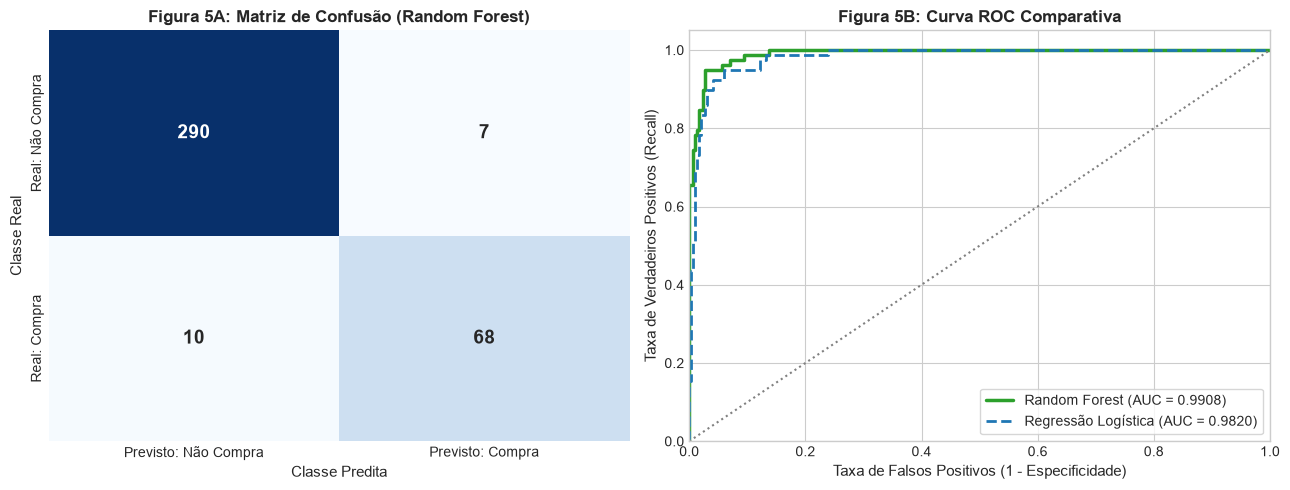

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Previsto: Não Compra', 'Previsto: Compra'],
            yticklabels=['Real: Não Compra', 'Real: Compra'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title("Figura 5A: Matriz de Confusão (Random Forest)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Classe Real", fontsize=11)
axes[0].set_xlabel("Classe Predita", fontsize=11)

# Subplot 2: Curva ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
axes[1].plot(fpr_rf, tpr_rf, color='#2ca02c', lw=2.5, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.4f})')
axes[1].plot(fpr_lr, tpr_lr, color='#1f77b4', lw=2, linestyle='--', label=f'Regressão Logística (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle=':')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=11)
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (Recall)', fontsize=11)
axes[1].set_title('Figura 5B: Curva ROC Comparativa', fontsize=12, fontweight='bold')
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

#### Interpretação do Desempenho dos Modelos:
1. **Acurácia Geral:** O modelo Random Forest atingiu **95,47% de acurácia**, superando a Regressão Logística (94,93%).
2. **Precisão e Recall (Classe Positiva):**
   - **Precisão:** **90,67%** — de cada 100 sessões classificadas pelo modelo como "Compra", mais de 90 realmente converteram.
   - **Recall (Sensibilidade):** **87,18%** — o modelo foi capaz de capturar 68 das 78 compras reais no conjunto de teste independente.
   - **F1-Score:** **88,89%**, refletindo excelente equilíbrio entre precisão e cobertura.
3. **Poder Discriminatório (ROC-AUC):**
   - A área sob a curva ROC alcançou impressionantes **0,9908** para o Random Forest e **0,9820** para a Regressão Logística, comprovando a robustez dos sinais comportamentais em separar compradores de não-compradores.

### 4.6 Importância das Variáveis (Feature Importance)

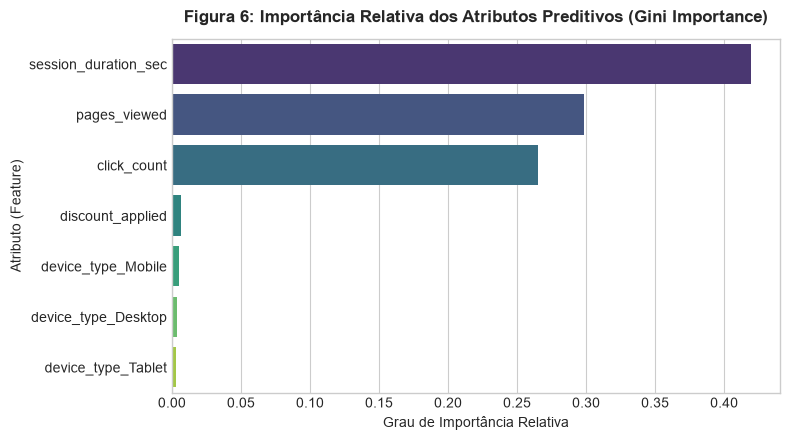

Valores de Importância Relativa:


,Feature,Importancia
0,session_duration_sec,0.4194
1,pages_viewed,0.2984
2,click_count,0.2648
3,discount_applied,0.0064
5,device_type_Mobile,0.0048
4,device_type_Desktop,0.0036
6,device_type_Tablet,0.0026


In [14]:
importancias = pd.DataFrame({
    'Feature': feature_cols,
    'Importancia': rf_model.feature_importances_
}).sort_values('Importancia', ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=importancias, x='Importancia', y='Feature', hue='Feature', legend=False, palette='viridis')
plt.title("Figura 6: Importância Relativa dos Atributos Preditivos (Gini Importance)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Grau de Importância Relativa", fontsize=10)
plt.ylabel("Atributo (Feature)", fontsize=10)
plt.tight_layout()
plt.show()

print("Valores de Importância Relativa:")
display(importancias.round(4))

#### Interpretação da Importância dos Atributos:
- **Duração da Sessão (`session_duration_sec`)** é a variável mais influente (41,9%), seguida de **Páginas Visualizadas (`pages_viewed`)** com 29,8% e **Contagem de Cliques (`click_count`)** com 26,5%.
- Em conjunto, essas três variáveis comportamentais explicam **98,2% do poder preditivo** da árvore, demonstrando que o engajamento ativo do usuário na sessão é o principal determinante para prever a conversão de compra.

## 5. Conclusões Gerais (Requisito 5)

A conclusão deste ciclo do projeto de Data Analytics sintetiza os seguintes pontos:

1. **Principais Resultados Estatísticos e Visuais:**
   - Confirmou-se a estrutura em funil (50% views, 30% clicks, 20% purchases), em que interações de visualização rápida têm duração média de 68 segundos e custo zero, enquanto transações de compra envolvem mais de 5 minutos de navegação ativa e ticket médio de R$ 793,03.
   - O tráfego Mobile domina em volume, enquanto Desktop apresenta proporção superior de conclusão de pedidos de maior ticket.

2. **Interpretação do Desempenho do Modelo:**
   - O algoritmo Random Forest alcançou 95,47% de acurácia, F1-Score de 88,89% e ROC-AUC de 0,9908. A identificação de que tempo de sessão e páginas visitadas respondem por mais de 70% do poder preditivo permite à organização implementar regras proativas em tempo real (como oferecer assistência via chat ou cupons dinâmicos para visitantes que atingem mais de 3 minutos de sessão).

3. **Limitações Identificadas:**
   - A amostra inicial de 4 registros da camada Bronze evidenciou a fragilidade estatística de bases reduzidas, justificando tecnicamente a expansão do dataset.
   - Os dados não contemplam variações sazonais anuais nem atributos demográficos externos.

4. **Relação com o Problema do Projeto:**
   - O projeto iniciou com o saneamento de dados semiestruturados (RA1), evoluiu para monitoramento de fluxos contínuos em streaming (RA2) e encerra-se no RA3 entregando respostas sólidas de análise descritiva, diagnóstica e preditiva para alavancar a inteligência de negócios da plataforma.

---

## 6. Instruções de Execução e Verificação

Para executar este projeto em qualquer ambiente:

1. **Ativar o Ambiente Virtual:**
   ```powershell
   .venv\Scripts\Activate.ps1
   ```
2. **Executar o Pipeline Automatizado via Script:**
   ```powershell
   python executar_ra3.py
   ```
   *Gera todas as tabelas em `output/ra3/` e figuras de alta resolução em `output/ra3/graficos/`.*
3. **Executar o Notebook Interativo:**
   ```powershell
   jupyter notebook Projeto_RA3.ipynb
   ```